# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
clients = pd.read_csv(RAW_CLIENTS)
clients.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001762,1973-09-17,Ж,казань,Массовый,Базовый,Дебетовая,29.12.2018,22.07.2023,Зарплата в другом банке,74200.0,Да,2024-06,4.0,573,Да
1,C003583,1974-02-22,М,казань,Зарплатный,Базовый,Дебетовая,29.09.2016,07.03.2021,Зарплата в другом банке,76000.0,Да,2024-05,NaN,316,Да
2,C004742,1968-08-09,М,Москва,Private,Платина,Дебетовая,24.05.2016,12.01.2019,Зарплата в нашем банке,338400.0,Да,2024-04,2.0,226,Да
3,C005442,1965-10-08,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,04.02.2020,01.07.2021,Зарплата в нашем банке,150100.0,Нет,NaN,NaN,497,Да
4,C003493,1990-08-29,Ж,Казань,Массовый,Золото,Дебетовая,24.04.2022,08.10.2022,Зарплата в нашем банке,32300.0,Нет,NaN,NaN,112,Нет


In [3]:
txn = pd.read_csv(RAW_TXN, sep = ';', encoding='cp1251')
txn.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990071,C003817,2023-11-26 15:21:53,"3190,05",RUB,Развлечения и досуг,7832,Токен,успешно
1,990033,C003658,2023-12-01 16:30:04,"2443,25",RUB,Продукты,5411,Карта,успешно
2,990141,C003289,2023-12-05 15:28:48,"161,38",RUB,Транспорт,4111,Онлайн-банк,успешно
3,990053,C001662,2023-12-09,"1042,76",RUB,Продукты,5411,СБП,отклонено
4,990084,C004074,2023-12-10,"1012,69",RUB,Развлечения и досуг,7832,Токен,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

In [4]:
clients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5696 entries, 0 to 5695
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5696 non-null   object 
 1   birth_date          5696 non-null   object 
 2   gender              5696 non-null   object 
 3   city                5696 non-null   object 
 4   segment             5696 non-null   object 
 5   loyalty_tier        5696 non-null   object 
 6   card_type           5696 non-null   object 
 7   registration_date   5696 non-null   object 
 8   card_open_date      5696 non-null   object 
 9   income_source       5696 non-null   object 
 10  monthly_income      5188 non-null   float64
 11  has_mobile_app      5696 non-null   object 
 12  app_last_login      3544 non-null   object 
 13  satisfaction_score  2285 non-null   float64
 14  branch_code         5696 non-null   int64  
 15  marketing_opt_in    5696 non-null   object 
dtypes: flo

In [5]:
txn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 613095 entries, 0 to 613094
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   txn_id        613095 non-null  int64 
 1   client_id     613095 non-null  object
 2   txn_datetime  613095 non-null  object
 3   amount        613095 non-null  object
 4   currency      613095 non-null  object
 5   category      613095 non-null  object
 6   mcc_code      613095 non-null  int64 
 7   channel       613095 non-null  object
 8   status        613095 non-null  object
dtypes: int64(2), object(7)
memory usage: 42.1+ MB


### 2.1. Объём, типы, ключи, единица наблюдения

In [6]:
cols = ["gender","city", "segment", "loyalty_tier", "income_source","has_mobile_app","marketing_opt_in","satisfaction_score"]

for col in cols:
    print(clients[col].unique())

['Ж' 'М']
['казань' 'Москва' 'Нижний Новгород' 'Казань' 'Санкт-Петербург' ' москва'
 'Санкт Петербург' 'Екатеринбург' 'Н. Новгород' 'СПб' 'г. Санкт-Петербург'
 'Новосибирск' 'МОСКВА' 'г. Москва' 'г. Новосибирск' 'г.Екатеринбург'
 'ЕКАТЕРИНБУРГ']
['Массовый' 'Зарплатный' 'Private' 'Премиальный']
['Базовый' 'Платина' 'Золото' 'Серебро']
['Зарплата в другом банке' 'Зарплата в нашем банке' 'Не указан']
['Да' 'Нет']
['Да' 'Нет']
[ 4. nan  2.  3.  5.  1.]


In [7]:
clients.dtypes

client_id              object
birth_date             object
gender                 object
city                   object
segment                object
loyalty_tier           object
card_type              object
registration_date      object
card_open_date         object
income_source          object
monthly_income        float64
has_mobile_app         object
app_last_login         object
satisfaction_score    float64
branch_code             int64
marketing_opt_in       object
dtype: object

In [8]:
cols = ["currency","category","mcc_code","channel",	"status"]

for col in cols:
    print(txn[col].unique())

['RUB' 'EUR' 'USD']
['Развлечения и досуг' 'Продукты' 'Транспорт' 'Кафе и рестораны' 'АЗС'
 'Онлайн-сервисы' 'Одежда и обувь' 'Аптеки' 'Связь и Интернет'
 'Связь и интернет' 'Кафе/рестораны' 'кафе и рестораны']
[7832 5411 4111 5812 5541 5815 5651 5912 4814]
['Токен' 'Карта' 'Онлайн-банк' 'СБП']
['успешно' 'отклонено' 'возврат']


### 2.2. Дубли

In [9]:
print(clients.shape[0], clients["client_id"].nunique())

5696 5641


In [10]:
dup_ids = clients["client_id"].duplicated(keep=False)
clients[dup_ids].sort_values("client_id")

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
2481,C000070,1966-09-10,Ж,Москва,Private,Платина,Премиальная,19.06.2017,24.12.2020,Зарплата в другом банке,400500.0,Да,2025-06,NaN,602,Да
3067,C000070,1966-09-10,Ж,Москва,Private,Платина,Премиальная,19.06.2017,24.12.2020,Зарплата в другом банке,400500.0,Да,2025-06,NaN,602,Да
2223,C000232,1976-12-26,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,12.07.2020,21.08.2024,Зарплата в другом банке,75100.0,Да,2025-02,NaN,138,Да
4879,C000232,1976-12-26,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,12.07.2020,21.08.2024,Зарплата в другом банке,75100.0,Да,2025-02,NaN,138,Да
5427,C000299,1982-04-14,М,Нижний Новгород,Зарплатный,Серебро,Кредитная,26.05.2014,15.11.2016,Зарплата в нашем банке,53900.0,Да,2025-05,NaN,672,Да
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
731,C005766,1976-04-30,Ж,Москва,Массовый,Серебро,Дебетовая,13.10.2020,25.10.2020,Зарплата в другом банке,60100.0,Да,2024-09,2.0,932,Да
3258,C005913,1965-10-02,Ж,Н. Новгород,Премиальный,Серебро,Кредитная,16.09.2016,15.03.2022,Зарплата в нашем банке,95400.0,Да,2024-11,3.0,716,Да
4842,C005913,1965-10-02,Ж,Н. Новгород,Премиальный,Серебро,Кредитная,16.09.2016,15.03.2022,Зарплата в нашем банке,95400.0,Да,2024-11,3.0,716,Да
3517,C005987,1937-02-25,М,г. Санкт-Петербург,Массовый,Серебро,Кредитная,21.08.2014,13.10.2016,Не указан,52600.0,Нет,NaN,NaN,679,Да


In [11]:
clients.duplicated().sum()  

np.int64(41)

In [12]:
clients = clients.drop_duplicates()
clients.duplicated().sum()

np.int64(0)

In [13]:
txn.duplicated().sum()

np.int64(1283)

In [14]:
txn = txn.drop_duplicates()
txn.duplicated().sum()

np.int64(0)

### 2.3. Соответствие данных описанию полей из задания

Типы не соответсвуют действительности, даты не datetime, количественные признаки не float

Некоторые данные принимают недопустимые значения

In [15]:
(clients["monthly_income"] <= 0).sum()

np.int64(62)

In [16]:
txn["amount"] = txn["amount"].str.replace(",", ".", regex=False).astype(float)

In [17]:
(txn["amount"] < 0).sum()

np.int64(7201)

In [18]:
txn[(txn["amount"] < 0) & (txn["status"] == "возврат")]

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
25,100016,C001576,2024-01-01 05:19:42,-5654.54,RUB,Одежда и обувь,5651,Карта,возврат
53,100044,C004106,2024-01-01 08:12:20,-2319.50,RUB,Одежда и обувь,5651,Карта,возврат
103,100094,C005686,2024-01-01 09:39:47,-851.54,RUB,Продукты,5411,Токен,возврат
321,100312,C003979,2024-01-01 13:58:07,-941.76,RUB,Онлайн-сервисы,5815,Онлайн-банк,возврат
422,100413,C002805,2024-01-01 15:20:06,-10799.98,RUB,Одежда и обувь,5651,Онлайн-банк,возврат
...,...,...,...,...,...,...,...,...,...
612663,715987,C001436,2025-06-30 15:26:28,-5244.38,RUB,Кафе и рестораны,5812,Карта,возврат
612689,716013,C002980,2025-06-30 15:51:02,-586.98,RUB,Связь и Интернет,4814,Карта,возврат
612858,716181,C001567,2025-06-30 18:19:55,-775.41,RUB,Онлайн-сервисы,5815,Токен,возврат
613041,990176,C004041,2025-11-28 15:56:31,-1465.83,RUB,Кафе и рестораны,5812,Онлайн-банк,возврат


In [19]:
s = txn["txn_datetime"].astype(str).str.strip()
parsed = pd.Series(pd.NaT, index=s.index)

formats = [
    "%d.%m.%Y %H:%M:%S",   # 28.07.2024 15:21:53
    "%d.%m.%Y %H:%M",      # 28.07.2024 15:21
    "%d.%m.%Y",            # 28.07.2024
]

for fmt in formats:
    mask = parsed.isna() & s.notna()
    parsed[mask] = pd.to_datetime(s[mask], format=fmt, errors="coerce")

txn["txn_datetime"] = parsed.dt.normalize()

In [20]:
txn.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990071,C003817,NaT,3190.05,RUB,Развлечения и досуг,7832,Токен,успешно
1,990033,C003658,NaT,2443.25,RUB,Продукты,5411,Карта,успешно
2,990141,C003289,NaT,161.38,RUB,Транспорт,4111,Онлайн-банк,успешно
3,990053,C001662,NaT,1042.76,RUB,Продукты,5411,СБП,отклонено
4,990084,C004074,NaT,1012.69,RUB,Развлечения и досуг,7832,Токен,успешно


### 2.4. Связь между таблицами

In [21]:
common_ids = set(clients["client_id"]) & set (txn["client_id"])
len(common_ids)

5633

В таблице txn есть данные о транзакциях 5633 клиентов из 5641

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

Найдено 45 строк-дубликатов о клиентах, 1283 строки-дубликата о транзакциях

Для 99.86% клиентов есть информация об их транзакциях

Некоторые города имеют несколько названий в таблице clients, а наименования одной и той же категории в транзакциях различаются. Это необходимо свести к единому образцу. Даты привести к формату datetime (например, для проверки корректности открытия счета и карты)

Некоторые записи содержат недопустимые значения (ежемесячный доход < 0, а вот сумма транзакции может быть отрицательной в случае возврата)

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

In [22]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

### 3.1. Типы, даты, числа

In [23]:
clients = clients.drop_duplicates(subset=["client_id"], keep="first")
print(clients.shape[0], clients["client_id"].nunique()) 

5641 5641


In [24]:
cleaning_log = pd.concat([cleaning_log, pd.DataFrame([{
    "field": "client_id",
    "issue": "дубликаты",
    "scope": "дубликаты",
    "n_rows": 55,
    "value_before": "5696 строк",
    "action": "удаление",
    "value_after": "5641 строк",
    "rationale": "один клиент должен иметь одну актуальную запись",
}])], ignore_index=True)

In [25]:
clients["monthly_income"] = clients["monthly_income"].mask(clients["monthly_income"] < 0)

In [26]:
cleaning_log = pd.concat([cleaning_log, pd.DataFrame([{
    "field": "monthly_income",
    "issue": "Недопустимые значения",
    "scope": "Значения < 0",
    "n_rows": 62,
    "value_before": "<0",
    "action": " -> nan ",
    "value_after": "nan",
    "rationale": "Доход может быть только положительным",
}])], ignore_index=True)

In [27]:
clients["birth_date"] = pd.to_datetime(clients["birth_date"], format="%Y-%m-%d", errors="coerce")

In [28]:
clients["registration_date"] = pd.to_datetime(clients["registration_date"], format="%d.%m.%Y", errors="coerce")
clients["card_open_date"] = pd.to_datetime(clients["card_open_date"], format="%d.%m.%Y", errors="coerce")

In [29]:
len(clients[clients["registration_date"] <=  clients["card_open_date"]])

5641

Все даты открытия карты позже, либо совпадают с датой регистрации в банке

### 3.2. Категориальные признаки

In [30]:
clients["city"].unique()

array(['казань', 'Москва', 'Нижний Новгород', 'Казань', 'Санкт-Петербург',
       ' москва', 'Санкт Петербург', 'Екатеринбург', 'Н. Новгород', 'СПб',
       'г. Санкт-Петербург', 'Новосибирск', 'МОСКВА', 'г. Москва',
       'г. Новосибирск', 'г.Екатеринбург', 'ЕКАТЕРИНБУРГ'], dtype=object)

In [31]:
n_rows = len(clients)
values_before = sorted(clients["city"].dropna().unique().tolist())

city_mapping = {
    "москва": "Москва",
    "казань": "Казань",
    "нижний новгород": "Нижний Новгород",
    "н. новгород": "Нижний Новгород",
    "санкт-петербург": "Санкт-Петербург",
    "санкт петербург": "Санкт-Петербург",
    "спб": "Санкт-Петербург",
    "екатеринбург": "Екатеринбург",
    "новосибирск": "Новосибирск",
}

def normalize_city(value):
    if pd.isna(value):
        return value
    s = str(value).strip().lower()     
    s = s.replace("г.", "").strip()     
    s = " ".join(s.split())           
    return city_mapping.get(s, value)   

clients["city"] = clients["city"].apply(normalize_city)

values_after = sorted(clients["city"].dropna().unique().tolist())
print(len(values_before), len(values_after))

17 6


In [32]:
cleaning_log = pd.concat([cleaning_log, pd.DataFrame([{
    "field": "city",
    "issue": "разные написания одного города",
    "scope": "регистр, пробелы, префикс «г.», аббревиатуры",
    "n_rows": 5641,
    "value_before": 17,
    "action": "исправлено",
    "value_after": 6,
    "rationale": "свести города к единому именованию для корректной группировки и сравнения",
}])], ignore_index=True)

In [33]:
txn["category"].unique()

array(['Развлечения и досуг', 'Продукты', 'Транспорт', 'Кафе и рестораны',
       'АЗС', 'Онлайн-сервисы', 'Одежда и обувь', 'Аптеки',
       'Связь и Интернет', 'Связь и интернет', 'Кафе/рестораны',
       'кафе и рестораны'], dtype=object)

In [34]:
n_rows = len(txn)
values_before = sorted(txn["category"].dropna().unique().tolist())

['Развлечения и досуг' 'Продукты' 'Транспорт' 'Кафе и рестораны' 'АЗС'
 'Онлайн-сервисы' 'Одежда и обувь' 'Аптеки' 'Связь и Интернет'
 'Связь и интернет' 'Кафе/рестораны' 'кафе и рестораны']

city_mapping = {
    "Кафе/рестораны": "Кафе и рестораны",
    "кафе и рестораны": "Кафе и рестораны"
}

def normalize_category(value):
    if pd.isna(value):
        return value  
    s = str(value)
    return city_mapping.get(s, value)   

txn["category"] = txn["category"].apply(normalize_category)

values_after = sorted(txn["category"].dropna().unique().tolist())
print(len(values_before), len(values_after))

12 10


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [35]:
clients.isna().mean() * 100

client_id              0.000000
birth_date             0.000000
gender                 0.000000
city                   0.000000
segment                0.000000
loyalty_tier           0.000000
card_type              0.000000
registration_date      0.000000
card_open_date         0.000000
income_source          0.000000
monthly_income         9.998227
has_mobile_app         0.000000
app_last_login        37.794717
satisfaction_score    60.024818
branch_code            0.000000
marketing_opt_in       0.000000
dtype: float64

In [36]:
no_app = clients[clients["has_mobile_app"] == "Нет"]
print(f"Количество клиентов без мобильного приложения: {len(no_app)}")
print(f"Из них с app_last_login = nan: {no_app['app_last_login'].isna().sum()} ( {round(2132/5641 * 100 ,6)} %) ")

Количество клиентов без мобильного приложения: 2132
Из них с app_last_login = nan: 2132 ( 37.794717 %) 


Уровень удовлетворенности клиента скорее всего является необязательным пунктом при заполнении анкет/опросов и люди игнорируют необязательные вопросы

Дата последнего использования nan, если человек не использует мобильное приложение

In [37]:
clients[clients["monthly_income"].isna()]

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
23,C002261,1981-07-13,М,Казань,Массовый,Базовый,Кредитная,2016-08-19,2020-01-15,Не указан,NaN,Нет,NaN,5.0,611,Да
33,C003456,1967-05-01,Ж,Москва,Массовый,Базовый,Дебетовая,2021-04-04,2023-01-06,Зарплата в другом банке,NaN,Нет,NaN,NaN,838,Да
37,C001491,1965-09-16,Ж,Санкт-Петербург,Премиальный,Золото,Дебетовая,2019-12-18,2025-03-23,Не указан,NaN,Нет,NaN,5.0,571,Да
43,C002132,1981-06-22,Ж,Екатеринбург,Зарплатный,Базовый,Дебетовая,2014-11-07,2018-08-30,Зарплата в нашем банке,NaN,Нет,NaN,NaN,296,Да
63,C005764,1994-09-27,Ж,Москва,Зарплатный,Базовый,Дебетовая,2021-03-01,2025-01-31,Не указан,NaN,Да,2024-10,5.0,746,Да
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5631,C000652,1937-05-03,М,Москва,Массовый,Базовый,Дебетовая,2016-02-29,2017-06-22,Зарплата в нашем банке,NaN,Нет,NaN,3.0,613,Да
5642,C001134,1977-10-02,Ж,Екатеринбург,Массовый,Серебро,Дебетовая,2013-02-07,2018-10-04,Не указан,NaN,Да,2024-10,NaN,149,Да
5643,C004761,1992-07-20,Ж,Новосибирск,Массовый,Серебро,Дебетовая,2017-09-06,2021-08-02,Не указан,NaN,Да,2024-07,NaN,545,Нет
5690,C005381,1972-08-11,Ж,Нижний Новгород,Массовый,Серебро,Дебетовая,2014-09-17,2018-05-02,Зарплата в другом банке,NaN,Нет,NaN,NaN,854,Нет


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

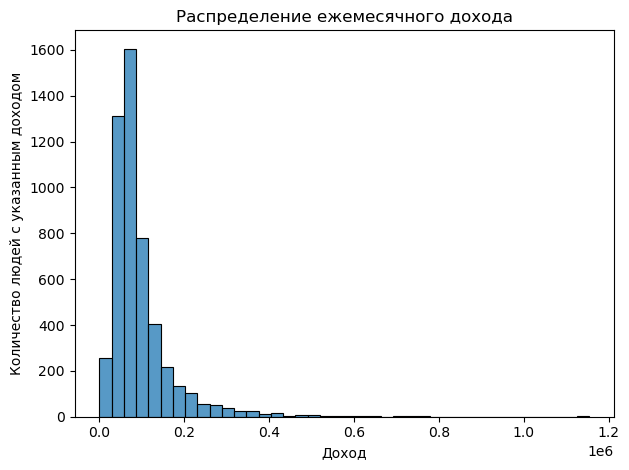

In [38]:
sns.histplot(data=clients,x="monthly_income", bins=40)
plt.title("Распределение ежемесячного дохода")
plt.xlabel("Доход")
plt.ylabel("Количество людей с указанным доходом")
plt.tight_layout()
plt.show()

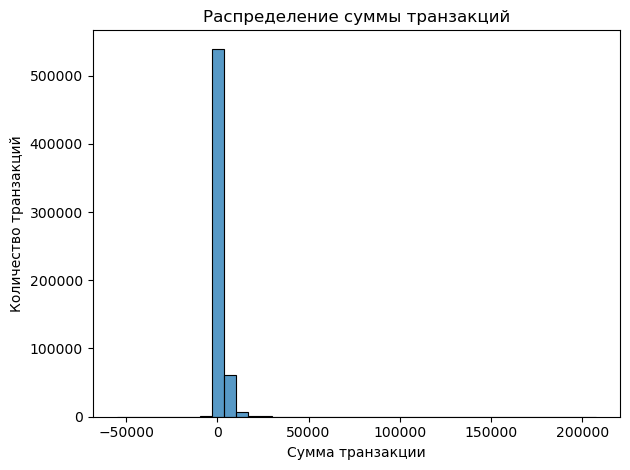

In [39]:
sns.histplot(data = txn, x = "amount", bins = 40)
plt.title("Распределение суммы транзакций")
plt.xlabel("Сумма транзакции")
plt.ylabel("Количество транзакций")
plt.tight_layout()
plt.show()

### 5.2. Частотные характеристики категориальных признаков

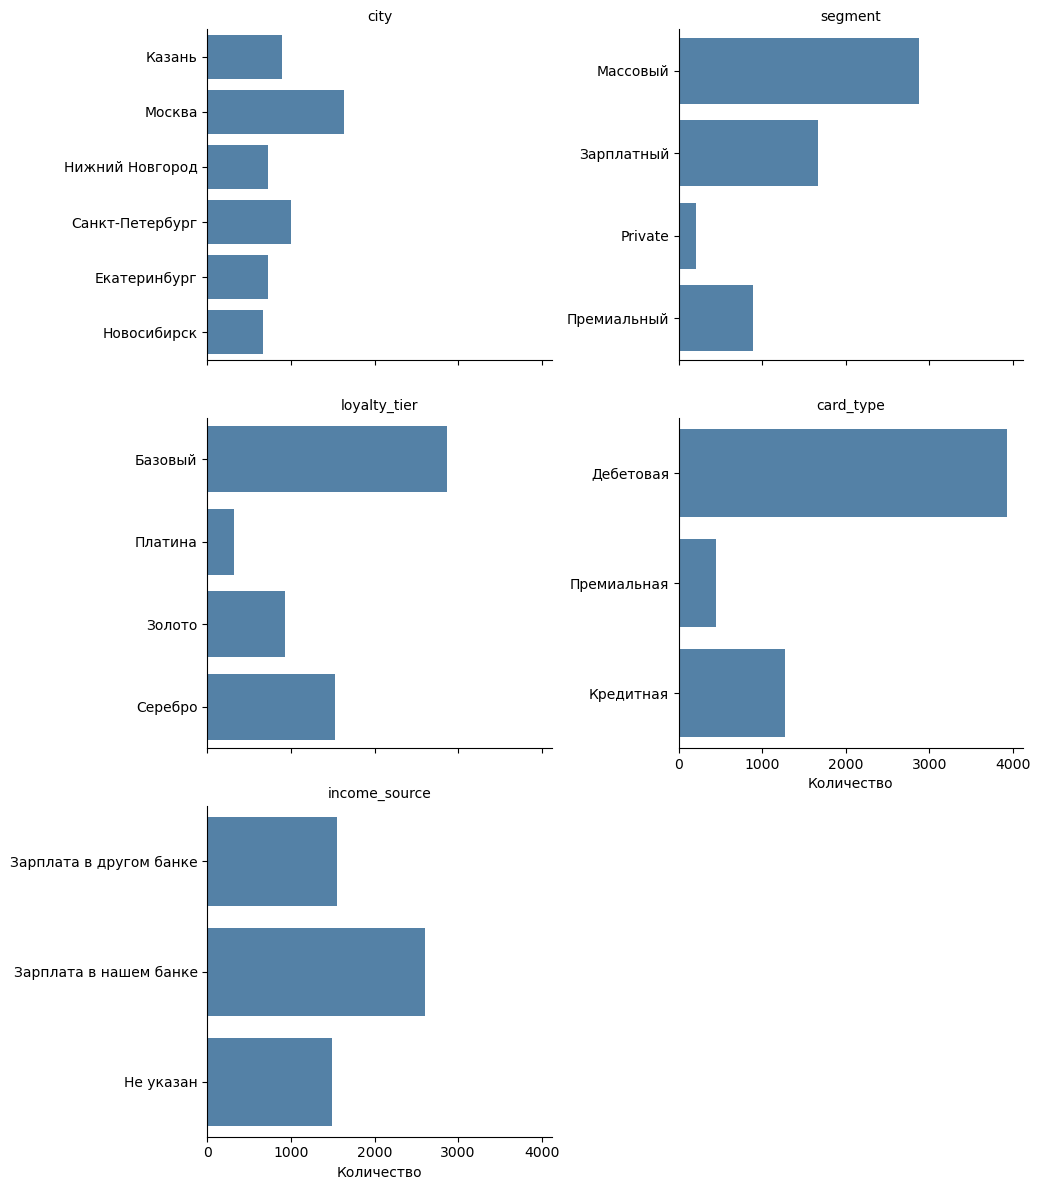

In [40]:
cat_cols = ["city", "segment", "loyalty_tier", "card_type", "income_source"]

long = clients[cat_cols].melt(var_name="feature", value_name="value")

g = sns.catplot(
    data=long,
    y="value",
    col="feature",
    col_wrap=2,
    kind="count",
    height=4,
    aspect=1.3,
    sharey=False,
    color="steelblue",
    order=None,
)
g.set_axis_labels("Количество", "")
g.set_titles("{col_name}")
plt.tight_layout()
plt.show()

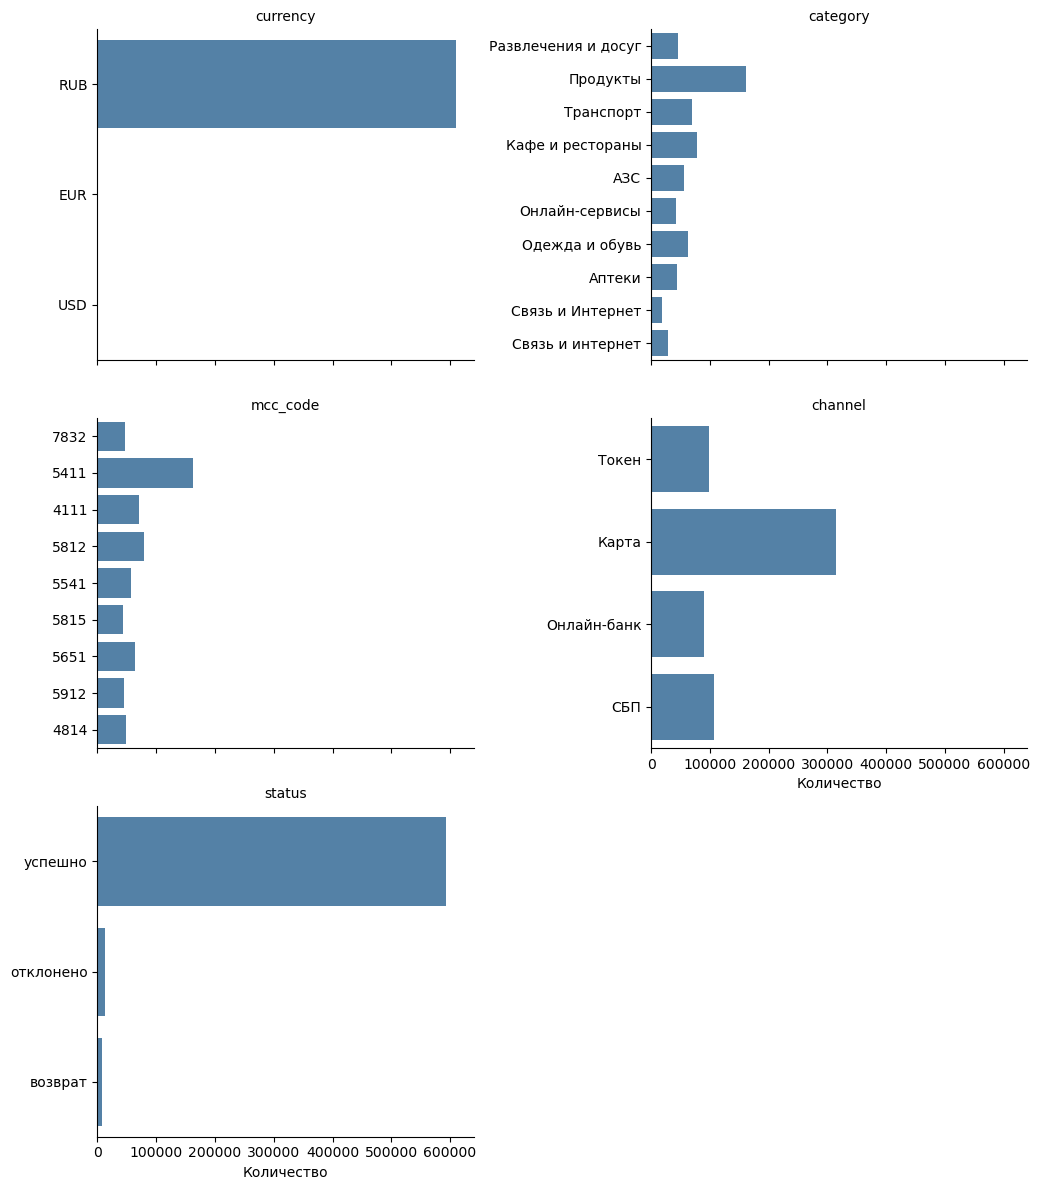

In [41]:
cat_cols = ["currency", "category", "mcc_code", "channel", "status"]

long = txn[cat_cols].melt(var_name="feature", value_name="value")

g = sns.catplot(
    data=long,
    y="value",
    col="feature",
    col_wrap=2,
    kind="count",
    height=4,
    aspect=1.3,
    sharey=False,
    color="steelblue",
    order=None,
)
g.set_axis_labels("Количество", "")
g.set_titles("{col_name}")
plt.tight_layout()
plt.show()

### 5.3. Динамика по месяцам

### 5.4. Разрезы и связи между признаками

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [42]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")